# Central Bank Web Scraping

### Import Libraries

In [92]:
!pip install requests beautifulsoup4 pandas lxml scrapy pytesseract pdf2image openpyxl pypdf


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [93]:
import pandas as pd
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
import requests
import scrapy
import time

import lxml
import html5lib

from pypdf import PdfReader

from PIL import Image
import pytesseract

# import io
import re
import os

from IPython.display import display, HTML
from urllib.parse import urljoin,urlparse

# Scrapy

In [94]:
# install some sinhala fonts in tesseract
!apt-get update -qq
!apt-get install -y tesseract-ocr tesseract-ocr-sin

'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.


In [95]:
!tesseract --list-langs

List of available languages in "F:\My PC\Applied Data Analysis\Second year\DA 2009\day 8 (23.08.2026)/tessdata/" (2):
eng
osd


In [96]:
# Define CBSL URL
BASE_URL = "https://www.cbsl.gov.lk/"

robots_url = urljoin(BASE_URL, "robots.txt")

response = requests.get(
    robots_url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

print("Status Code:", response.status_code)
print(response.text[:50000])

Status Code: 200
#
# robots.txt
#
# This file is to prevent the crawling and indexing of certain parts
# of your site by web crawlers and spiders run by sites like Yahoo!
# and Google. By telling these "robots" where not to go on your site,
# you save bandwidth and server resources.
#
# This file will be ignored unless it is at the root of your host:
# Used:    http://example.com/robots.txt
# Ignored: http://example.com/site/robots.txt
#
# For more information about the robots.txt standard, see:
# http://www.robotstxt.org/robotstxt.html

User-agent: *
Crawl-delay: 10
# CSS, JS, Images
Allow: /misc/*.css$
Allow: /misc/*.css?
Allow: /misc/*.js$
Allow: /misc/*.js?
Allow: /misc/*.gif
Allow: /misc/*.jpg
Allow: /misc/*.jpeg
Allow: /misc/*.png
Allow: /modules/*.css$
Allow: /modules/*.css?
Allow: /modules/*.js$
Allow: /modules/*.js?
Allow: /modules/*.gif
Allow: /modules/*.jpg
Allow: /modules/*.jpeg
Allow: /modules/*.png
Allow: /profiles/*.css$
Allow: /profiles/*.css?
Allow: /profiles/*.js$
All

In [97]:
# Create the Requests function
HEADERS = {
    "User-Agent": "Mozilla/5.0"
}

def get_page(url):

    response = requests.get(
        url,
        headers=HEADERS,
        timeout=30
    )

    response.raise_for_status()
    return response.text

In [98]:
# test Requests function
html = get_page(BASE_URL)
print("Downloaded:", len(html), "characters")

Downloaded: 170558 characters


In [99]:
try:
    homepage = requests.get(
        BASE_URL,
        headers=HEADERS,
        timeout=30
    )

    print("Homepage Status:",homepage.status_code)
    print("Final URL:",homepage.url)
    print("HTML Size:",len(homepage.text))

except Exception as e:
    print("Homepage error:",e)

Homepage Status: 200
Final URL: https://www.cbsl.gov.lk/
HTML Size: 170558


In [100]:
!scrapy startproject cbsl_scraper

Error: scrapy.cfg already exists in F:\My PC\Applied Data Analysis\Second year\DA 2009\Group_Project\cbsl_scraper


In [101]:
%cd cbsl_scraper

f:\My PC\Applied Data Analysis\Second year\DA 2009\Group_Project\cbsl_scraper


In [102]:
%%writefile cbsl_scraper/settings.py

BOT_NAME = "cbsl_scraper"

SPIDER_MODULES = ["cbsl_scraper.spiders"]

NEWSPIDER_MODULE = "cbsl_scraper.spiders"

ROBOTSTXT_OBEY = True

CONCURRENT_REQUESTS_PER_DOMAIN = 1

DOWNLOAD_DELAY = 10

DOWNLOAD_TIMEOUT = 60

RETRY_TIMES = 2

USER_AGENT = (
    "Mozilla/5.0 "
    "(Windows NT 10.0; Win64; x64) "
    "AppleWebKit/537.36 "
    "(KHTML, like Gecko) "
    "Chrome/120.0 Safari/537.36"
)

FEED_EXPORT_ENCODING = "utf-8"

LOG_LEVEL = "INFO"

Overwriting cbsl_scraper/settings.py


In [ ]:
%%writefile cbsl_scraper/spiders/cbsl_links.py

import scrapy
from urllib.parse import urlparse

class CbslLinksSpider(scrapy.Spider):

    name = "cbsl_links"

    allowed_domains = ["www.cbsl.gov.lk"]

    start_urls = ["https://www.cbsl.gov.lk/"]

    custom_settings = {
        "DEPTH_LIMIT": 2
        }

    relevant_keywords = [
        "inflation",
        "exchange",
        "monetary",
        "rates-and-indicators"
    ]

    def parse(self, response):

        self.logger.info(f"Opened: {response.url}")
        # Extract normal links

        for link in response.css("a[href]"):
            href = link.attrib.get("href")

            if not href:
                continue

            text = " ".join(link.css("::text").getall()).strip()
            full_url = response.urljoin(href)
            parsed = urlparse(full_url)

            if (parsed.netloc != "www.cbsl.gov.lk"):
                continue

            yield {
                "link_type": "a",
                "link_text": text,
                "url": full_url,
                "source_page": response.url
            }

            combined = (text + " " + full_url).lower()

            relevant = any(
                keyword in combined
                for keyword in self.relevant_keywords
            )

            # Follow relevant pages
            if relevant:
                if not full_url.lower().endswith((".pdf",".xls",".xlsx",".csv")):
                    yield response.follow(
                        full_url,
                        callback=self.parse
                    )

        # Extract iframe links

        for iframe in response.css("iframe[src]"):
            src = iframe.attrib.get("src")
            if not src:
                continue

            full_url = response.urljoin(src)
            parsed = urlparse(full_url)

            if (parsed.netloc != "www.cbsl.gov.lk"):
                continue

            yield {
                "link_type": "iframe",
                "link_text": "iframe",
                "url": full_url,
                "source_page": response.url
            }

            # Follow iframe
            yield response.follow(
                full_url,
                callback=self.parse
            )

Overwriting cbsl_scraper/spiders/cbsl_links.py


In [104]:
!scrapy crawl cbsl_links -O ../CBSL_All_Links.csv

2026-10-09 22:05:25 [scrapy.utils.log] INFO: Scrapy 2.19.0 started (bot: cbsl_scraper)
2026-10-09 22:05:26 [scrapy.utils.log] INFO: Versions:
{'lxml': '6.1.1',
 'libxml2': '2.11.9',
 'cssselect': '1.5.0',
 'parsel': '1.12.1',
 'w3lib': '2.5.0',
 'Twisted': '26.4.0',
 'Python': '3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 '
           '64 bit (AMD64)]',
 'pyOpenSSL': '26.4.0 (OpenSSL 4.0.3 29 Sep 2026)',
 'cryptography': '50.0.2',
 'Platform': 'Windows-10-10.0.19045-SP0'}
2026-10-09 22:05:26 [scrapy.addons] INFO: Enabled addons:
[]
2026-10-09 22:05:26 [scrapy.extensions.telnet] INFO: Telnet Password: ae5f6b9454088161
2026-10-09 22:05:27 [scrapy.middleware] INFO: Enabled extensions:
['scrapy.extensions.corestats.CoreStats',
 'scrapy.extensions.logcount.LogCount',
 'scrapy.extensions.telnet.TelnetConsole',
 'scrapy.extensions.feedexport.FeedExporter',
 'scrapy.extensions.logstats.LogStats',
 'scrapy.extensions.remote_control.RemoteControl']
2026-10-09 22:05:27 [scrapy

In [105]:
%cd ..

f:\My PC\Applied Data Analysis\Second year\DA 2009\Group_Project


In [106]:
all_links = pd.read_csv("CBSL_All_Links.csv")

display(all_links.head(20))

,link_type,link_text,url,source_page
0,a,Skip to main content,https://www.cbsl.gov.lk/#main-content,https://www.cbsl.gov.lk/
1,a,NaN,https://www.cbsl.gov.lk/en,https://www.cbsl.gov.lk/
2,a,NaN,https://www.cbsl.gov.lk/en,https://www.cbsl.gov.lk/
3,a,English,https://www.cbsl.gov.lk/en,https://www.cbsl.gov.lk/
4,a,සිංහල,https://www.cbsl.gov.lk/si,https://www.cbsl.gov.lk/
5,a,தமிழ்,https://www.cbsl.gov.lk/ta,https://www.cbsl.gov.lk/
6,a,NaN,https://www.cbsl.gov.lk/rss-feeds,https://www.cbsl.gov.lk/
7,a,ABOUT,https://www.cbsl.gov.lk/#,https://www.cbsl.gov.lk/
8,a,About the Bank,https://www.cbsl.gov.lk/#,https://www.cbsl.gov.lk/
9,a,Overview,https://www.cbsl.gov.lk/en/about/about-the-bank/overview,https://www.cbsl.gov.lk/


In [107]:
print("Total links:",len(all_links))

Total links: 10507


In [108]:
all_links = (
    all_links
    .drop_duplicates(subset=["url"])
    .reset_index(drop=True)
)

print("Unique links:",len(all_links))

Unique links: 749


In [109]:
keywords = [
    "inflation",
    "exchange rate",
    "exchange-rate",
    "exchange",
    "monetary policy",
    "monetary",
    "policy"
]

pattern = "|".join(map(re.escape,keywords))

# Step 1: Search keywords in link text
text_match = all_links["link_text"].fillna("").str.contains(
    pattern, case=False, regex=True
)

# Step 2: Search keywords in URL
url_match = all_links["url"].fillna("").str.contains(
    pattern, case=False, regex=True
)

# Step 3: Keep rows matching either condition
relevant_links = all_links[text_match | url_match].copy()

In [110]:
display(relevant_links)

,link_type,link_text,url,source_page
21,a,MONETARY POLICY,https://www.cbsl.gov.lk/en/monetary-policy-2026,https://www.cbsl.gov.lk/
36,a,Domestic Foreign Exchange Market,https://www.cbsl.gov.lk/en/financial-system/financial-markets/domestic-foreign-exchange-market,https://www.cbsl.gov.lk/
40,a,Equity Market,https://www.cbsl.gov.lk/en/financial-system/financial-markets/colombo-stock-exchange-share-equity-market,https://www.cbsl.gov.lk/
55,a,Public Currency Exchange Counter,https://www.cbsl.gov.lk/en/notes-coins/notes-and-coins/public-currency-exchange-counter,https://www.cbsl.gov.lk/
65,a,Foreign Exchange,https://www.cbsl.gov.lk/en/laws/directions-circulars-guidelines-on-foreign-exchange,https://www.cbsl.gov.lk/
...,...,...,...,...
742,a,ABOUT,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-august#,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-august
743,a,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary-policy-report-2026-august.pdf,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-august
744,a,Skip to main content,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february#main-content,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february
747,a,ABOUT,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february#,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february


In [111]:
def classify_link(row):
    combined = (str(row["link_text"]) + " " + str(row["url"])).lower()

    if "inflation" in combined:
        return "Inflation"

    elif "exchange" in combined:
        return "Exchange Rate"

    elif ("monetary" in combined or "policy" in combined):
        return "Monetary Policy"
    return "Other"

In [112]:
relevant_links["category"] = relevant_links.apply(classify_link,axis=1)

In [113]:
display(relevant_links[["category","link_text","url"]])

,category,link_text,url
21,Monetary Policy,MONETARY POLICY,https://www.cbsl.gov.lk/en/monetary-policy-2026
36,Exchange Rate,Domestic Foreign Exchange Market,https://www.cbsl.gov.lk/en/financial-system/financial-markets/domestic-foreign-exchange-market
40,Exchange Rate,Equity Market,https://www.cbsl.gov.lk/en/financial-system/financial-markets/colombo-stock-exchange-share-equity-market
55,Exchange Rate,Public Currency Exchange Counter,https://www.cbsl.gov.lk/en/notes-coins/notes-and-coins/public-currency-exchange-counter
65,Exchange Rate,Foreign Exchange,https://www.cbsl.gov.lk/en/laws/directions-circulars-guidelines-on-foreign-exchange
...,...,...,...
742,Monetary Policy,ABOUT,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-august#
743,Monetary Policy,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary-policy-report-2026-august.pdf
744,Monetary Policy,Skip to main content,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february#main-content
747,Monetary Policy,ABOUT,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-february#


In [114]:
relevant_links.to_csv("CBSL_Relevant_Links.csv",index=False)

# News

In [ ]:
# headers = {"User-Agent": "Mozilla/5.0 (University project)"}
os.makedirs("CSV_folder")
soup = BeautifulSoup(requests.get(BASE_URL + "/en", headers=HEADERS, timeout=30).text, "lxml")

news = []

for row in soup.select("div.view-front-page-news div.views-row"):
    #get the heading of the link
    a = row.select_one("h2.node-title a")
    if not a:
        continue
    # get the desctiption of the news
    summary = row.select_one("div.node-content")
    news.append({
        "NEWS": a.get_text(strip=True),
        "NEWS IN DETAILS": summary.get_text(" ", strip=True).replace("READ MORE", "").strip() if summary else None,
    })

df_news = pd.DataFrame(news)
pd.set_option("display.max_colwidth", 12000)
display(HTML(df_news.to_html(index=False)))
print(len(df_news), "news items found")
df_news.to_csv(f"{"CSV_folder"}/cbsl_news.csv", index=False)

NEWS,NEWS IN DETAILS
The Central Bank of Sri Lanka Inaugurates The Financial Literacy Month – 2026,"The Central Bank of Sri Lanka (CBSL) inaugurates the Financial Literacy Month – 2026 (FinLit Month) on 08 October 2026, commencing with “FinLit Expo – Colombo” at the Centre for Banking Studies, Rajagiriya. This national programme brings together a range of interventions across the island to strengthen financial knowledge, promote responsible financial behaviour and advance financial inclusion. Financial Literacy Month forms part of a broader national initiative under the Financial Literacy Roadmap for Sri Lanka, implemented under the National Financial Inclusion Strategy (NFIS)."
The Central Bank of Sri Lanka releases the Key Findings of the Systemic Risk Survey (SRS) – H2 of 2026,"The Central Bank of Sri Lanka (CBSL) has released the key findings of the latest Systemic Risk Survey (SRS) conducted for the second half of 2026 (H2 of 2026), capturing financial market participants’ perceptions of risks to, and their confidence in, the Sri Lankan financial system. The survey was conducted from 17 July 2026 to 14 August 2026."
IMF Reaches Staff-Level Agreement on the Seventh Review under the Extended Fund Facility with Sri Lanka,The International Monetary Fund (IMF) staff and the Sri Lankan authorities have reached staff-level agreement on the Seventh Review under the 4-year Extended Fund Facility (EFF) arrangement and concluded the 2026 Article IV Consultation discussions.
Sri Lanka’s Inflation Target is set at 5% for the next three years,"The Minister of Finance, Planning and Economic Development and the President of Sri Lanka, Hon. Anura Kumara Dissanayake, and the Governor of the Central Bank of Sri Lanka, Dr. P Nandalal Weerasinghe, signed a new Monetary Policy Framework Agreement (MPFA) in terms of Section 26 of the Central Bank of Sri Lanka Act, No. 16 of 2023 (CBA) on 01 October 2026. The Agreement was published in Government Gazette Extraordinary No. 2508/28 dated 01 October 2026."
CCPI-based headline inflation remained unchanged in September 2026,"The Colombo Consumer Price Index (CCPI, 2021=100) based headline inflation (year-on-year, Y-o-Y) remained unchanged at 8.0% in September 2026 compared to August 2026."
External Sector Performance - August 2026,"The external current account recorded a surplus of US$ 133 million in August 2026 following four consecutive months of deficits. The surplus was supported by the lower trade deficit compared to recent months, reflecting lower import expenditure. The current account recorded a cumulative deficit of US$ 291 million during January-August 2026, reflecting pressures on the external sector stemming from the escalation of the Middle East conflict."


6 news items found


## Inflation

In [117]:
tittle = soup.find("title").text
print(tittle)

Central Bank of Sri Lanka


In [ ]:
# filtering  the inflation table
result = relevant_links[
    relevant_links["url"].str.contains("inflationwindow.php", na=False)
] 

display(result)

,link_type,link_text,url,source_page,category
402,iframe,iframe,https://www.cbsl.gov.lk/cbsl_custom/inflation/inflationwindow.php,https://www.cbsl.gov.lk/en/measures-of-consumer-price-inflation,Inflation


In [130]:
url = result['url'].iloc[0]
print(url)

https://www.cbsl.gov.lk/cbsl_custom/inflation/inflationwindow.php


In [ ]:
# url = relevant_links.loc[387, "url"]
# print(url)

In [131]:
# url = "https://www.cbsl.gov.lk/cbsl_custom/inflation/inflationwindow.php"

tables = pd.read_html(url)
print("Number of tables : ", len(tables))

Number of tables :  2


# Table 1

In [132]:
tables[0]

,0,1,2,3,4
0,Date,"Colombo Consumer Price Index (CCPI) (CCPI, 2021=100)","Colombo Consumer Price Index (CCPI) (CCPI, 2021=100)","National Consumer Price Index (NCPI) (NCPI, 2021=100)","National Consumer Price Index (NCPI) (NCPI, 2021=100)"
1,NaN,Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y),Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y)
2,2026,2026,2026,2026,2026
3,January,2.30,2.30,2.40,2.20
4,February,1.60,2.10,1.60,2.20
5,March,2.20,2.50,2.40,2.70
6,April,5.40,3.80,4.70,4.40
7,May,5.50,3.90,5.40,4.50
8,June,6.80,4.00,6.50,5.00
9,July,7.30,4.40,7.20,6.00


In [ ]:
# os.makedirs("CSV_folder",exist_ok=True)

# 2026

In [133]:
df = pd.DataFrame(tables[0])
df_2026 = df.iloc[0:12]

df_2026 = df_2026.drop([0,1,2])

df_2026 = df_2026.rename(columns={
    df_2026.columns[0]:"Date-2026",
    df_2026.columns[1]:"CCPI Headline Inflation",
    df_2026.columns[2]:"CCPI Core Inflation",
    df_2026.columns[3]:"NCPI Headline Inflation",
    df_2026.columns[4]:"NCPI Core Inflation"
})

display(HTML(df_2026.to_html(index=False)))
df_2026.to_csv(f"{"CSV_folder"}/2026-inflation.csv",index=False)

Date-2026,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,2.30,2.30,2.40,2.20
February,1.60,2.10,1.60,2.20
March,2.20,2.50,2.40,2.70
April,5.40,3.80,4.70,4.40
May,5.50,3.90,5.40,4.50
June,6.80,4.00,6.50,5.00
July,7.30,4.40,7.20,6.00
August,8.00,5.10,8.10,6.30
September,8.00,5.40,-,-


# 2025

In [134]:
df = pd.DataFrame(tables[0])
df_2025 = df.iloc[13:25]

df_2025 = df_2025.rename(columns={
    df_2025.columns[0]:"Date-2025",
    df_2025.columns[1]:"CCPI Headline Inflation",
    df_2025.columns[2]:"CCPI Core Inflation",
    df_2025.columns[3]:"NCPI Headline Inflation",
    df_2025.columns[4]:"NCPI Core Inflation",
})

display(HTML(df_2025.to_html(index=False)))

df_2025.to_csv(f"{"CSV_folder"}/2025-inflation.csv",index=False)

Date-2025,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,-4.00,1.20,-4.00,-0.20
February,-4.20,0.70,-3.90,-0.60
March,-2.60,0.70,-1.90,-0.60
April,-2.00,0.80,-0.80,-0.10
May,-0.70,1.20,0.60,0.30
June,-0.60,1.50,0.30,0.60
July,-0.30,1.60,0.70,0.90
August,1.20,2.00,1.50,1.50
September,1.50,2.00,2.10,1.90
October,2.10,2.20,2.70,2.10


# 2024

In [135]:
df = pd.DataFrame(tables[0])
df_2024 =df.iloc[26:]

df_2024 = df_2024.rename(columns={
    df_2024.columns[0] : "Date-2024",
    df_2024.columns[1] : "CCPI Headline Inflation",
    df_2024.columns[2] : "CCPI Core Inflation",
    df_2024.columns[3] : "NCPI Headline Inflation",
    df_2024.columns[4] : "NCPI Core Inflation"
})

display(HTML(df_2024.to_html(index=False)))

df_2024.to_csv(f"{"CSV_folder"}/2024-inflation.csv",index=False)

Date-2024,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,6.40,2.20,6.50,2.20
February,5.90,2.80,5.10,2.70
March,0.90,3.10,2.50,3.40
April,1.50,3.40,2.70,3.00
May,0.90,3.50,1.60,3.10
June,1.70,4.40,2.40,3.90
July,2.40,4.40,2.50,3.00
August,0.50,3.60,1.10,2.30
September,-0.50,3.30,-0.20,1.90
October,-0.80,3.00,-0.70,1.70


# Table 2

In [136]:
tables[1]

,0,1,2,3,4
0,Date,"Colombo Consumer Price Index (CCPI) (CCPI, 2013=100)","Colombo Consumer Price Index (CCPI) (CCPI, 2013=100)","National Consumer Price Index (NCPI) (NCPI, 2013=100)","National Consumer Price Index (NCPI) (NCPI, 2013=100)"
1,NaN,Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y),Headline Inflation (Y-o-Y),Core Inflation (Y-o-Y)
2,2022,2022,2022,2022,2022
3,January,14.20,9.90,16.80,12.90
4,February,15.10,10.90,17.50,14.10
5,March,18.70,13.00,21.50,17.30
6,April,29.80,22.00,33.80,27.90
7,May,39.10,28.40,45.30,37.70
8,June,54.60,39.90,58.90,49.30
9,July,60.80,44.30,66.70,57.30


# 2022

In [137]:
df = pd.DataFrame(tables[1])
df_2022 = df.loc[0:14]

df_2022 = df_2022.drop([0,1,2])

df_2022 = df_2022.rename(columns={
    df_2022.columns[0]: 'Date-2022',
    df_2022.columns[1]: 'CCPI Headline Inflation',
    df_2022.columns[2]: 'CCPI Core Inflation',
    df_2022.columns[3]: 'NCPI Headline Inflation',
    df_2022.columns[4]: 'NCPI Core Inflation'
})

df_2022

display(HTML(df_2022.to_html(index=False)))
df_2022.to_csv(f"{"CSV_folder"}/2022-inflation.csv",index=False)



Date-2022,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,14.20,9.90,16.80,12.90
February,15.10,10.90,17.50,14.10
March,18.70,13.00,21.50,17.30
April,29.80,22.00,33.80,27.90
May,39.10,28.40,45.30,37.70
June,54.60,39.90,58.90,49.30
July,60.80,44.30,66.70,57.30
August,64.30,46.60,70.20,60.50
September,69.80,50.20,73.70,64.10
October,66.00,49.70,70.60,62.40


# 2021

In [138]:
df = pd.DataFrame(tables[1])
df_2021 = df.iloc[16:28]

df_2021 = df_2021.rename(columns={
    df_2021.columns[0]: 'Date-2021',
    df_2021.columns[1]: 'CCPI Headline Inflation',
    df_2021.columns[2]: 'CCPI Core Inflation',
    df_2021.columns[3]: 'NCPI Headline Inflation',
    df_2021.columns[4]: 'NCPI Core Inflation'
})

display(HTML(df_2021.to_html(index=False)))

df_2021.to_csv(f"{"CSV_folder"}/2021-inflation.csv",index=False)

Date-2021,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,3.00,2.70,3.70,4.20
February,3.30,2.60,4.20,4.10
March,4.10,3.10,5.10,4.30
April,3.90,3.00,5.50,4.10
May,4.50,3.20,6.10,4.20
June,5.20,3.20,6.10,4.10
July,5.70,3.70,6.80,4.40
August,6.00,4.10,6.70,4.70
September,5.70,5.00,6.20,4.80
October,7.60,6.30,8.30,7.20


# 2020

In [139]:
df = pd.DataFrame(tables[1])
df_2020 = df.iloc[29:]

df_2020 = df_2020.rename(columns={
    df_2020.columns[0] :"Date-2020",
    df_2020.columns[1] :"CCPI Headline Inflation",
    df_2020.columns[2] :"CCPI Core Inflation",
    df_2020.columns[3] :"NCPI Headline Inflation",
    df_2020.columns[4] :"NCPI Core Inflation"
})

display(HTML(df_2020.to_html(index=False)))

df_2020.to_csv(f"{"CSV_folder"}/2020-inflation.csv",index=False)

Date-2020,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation
January,5.70,3.00,7.60,3.90
February,6.20,3.20,8.10,3.40
March,5.40,2.90,7.00,3.20
April,5.20,3.10,5.90,3.20
May,4.00,2.90,5.20,3.70
June,3.90,3.10,6.30,4.40
July,4.20,3.20,6.10,4.50
August,4.10,3.20,6.20,4.60
September,4.00,2.90,6.40,4.80
October,4.00,3.00,5.50,4.50


# Visualization

In [140]:
os.makedirs("plots",exist_ok=True)

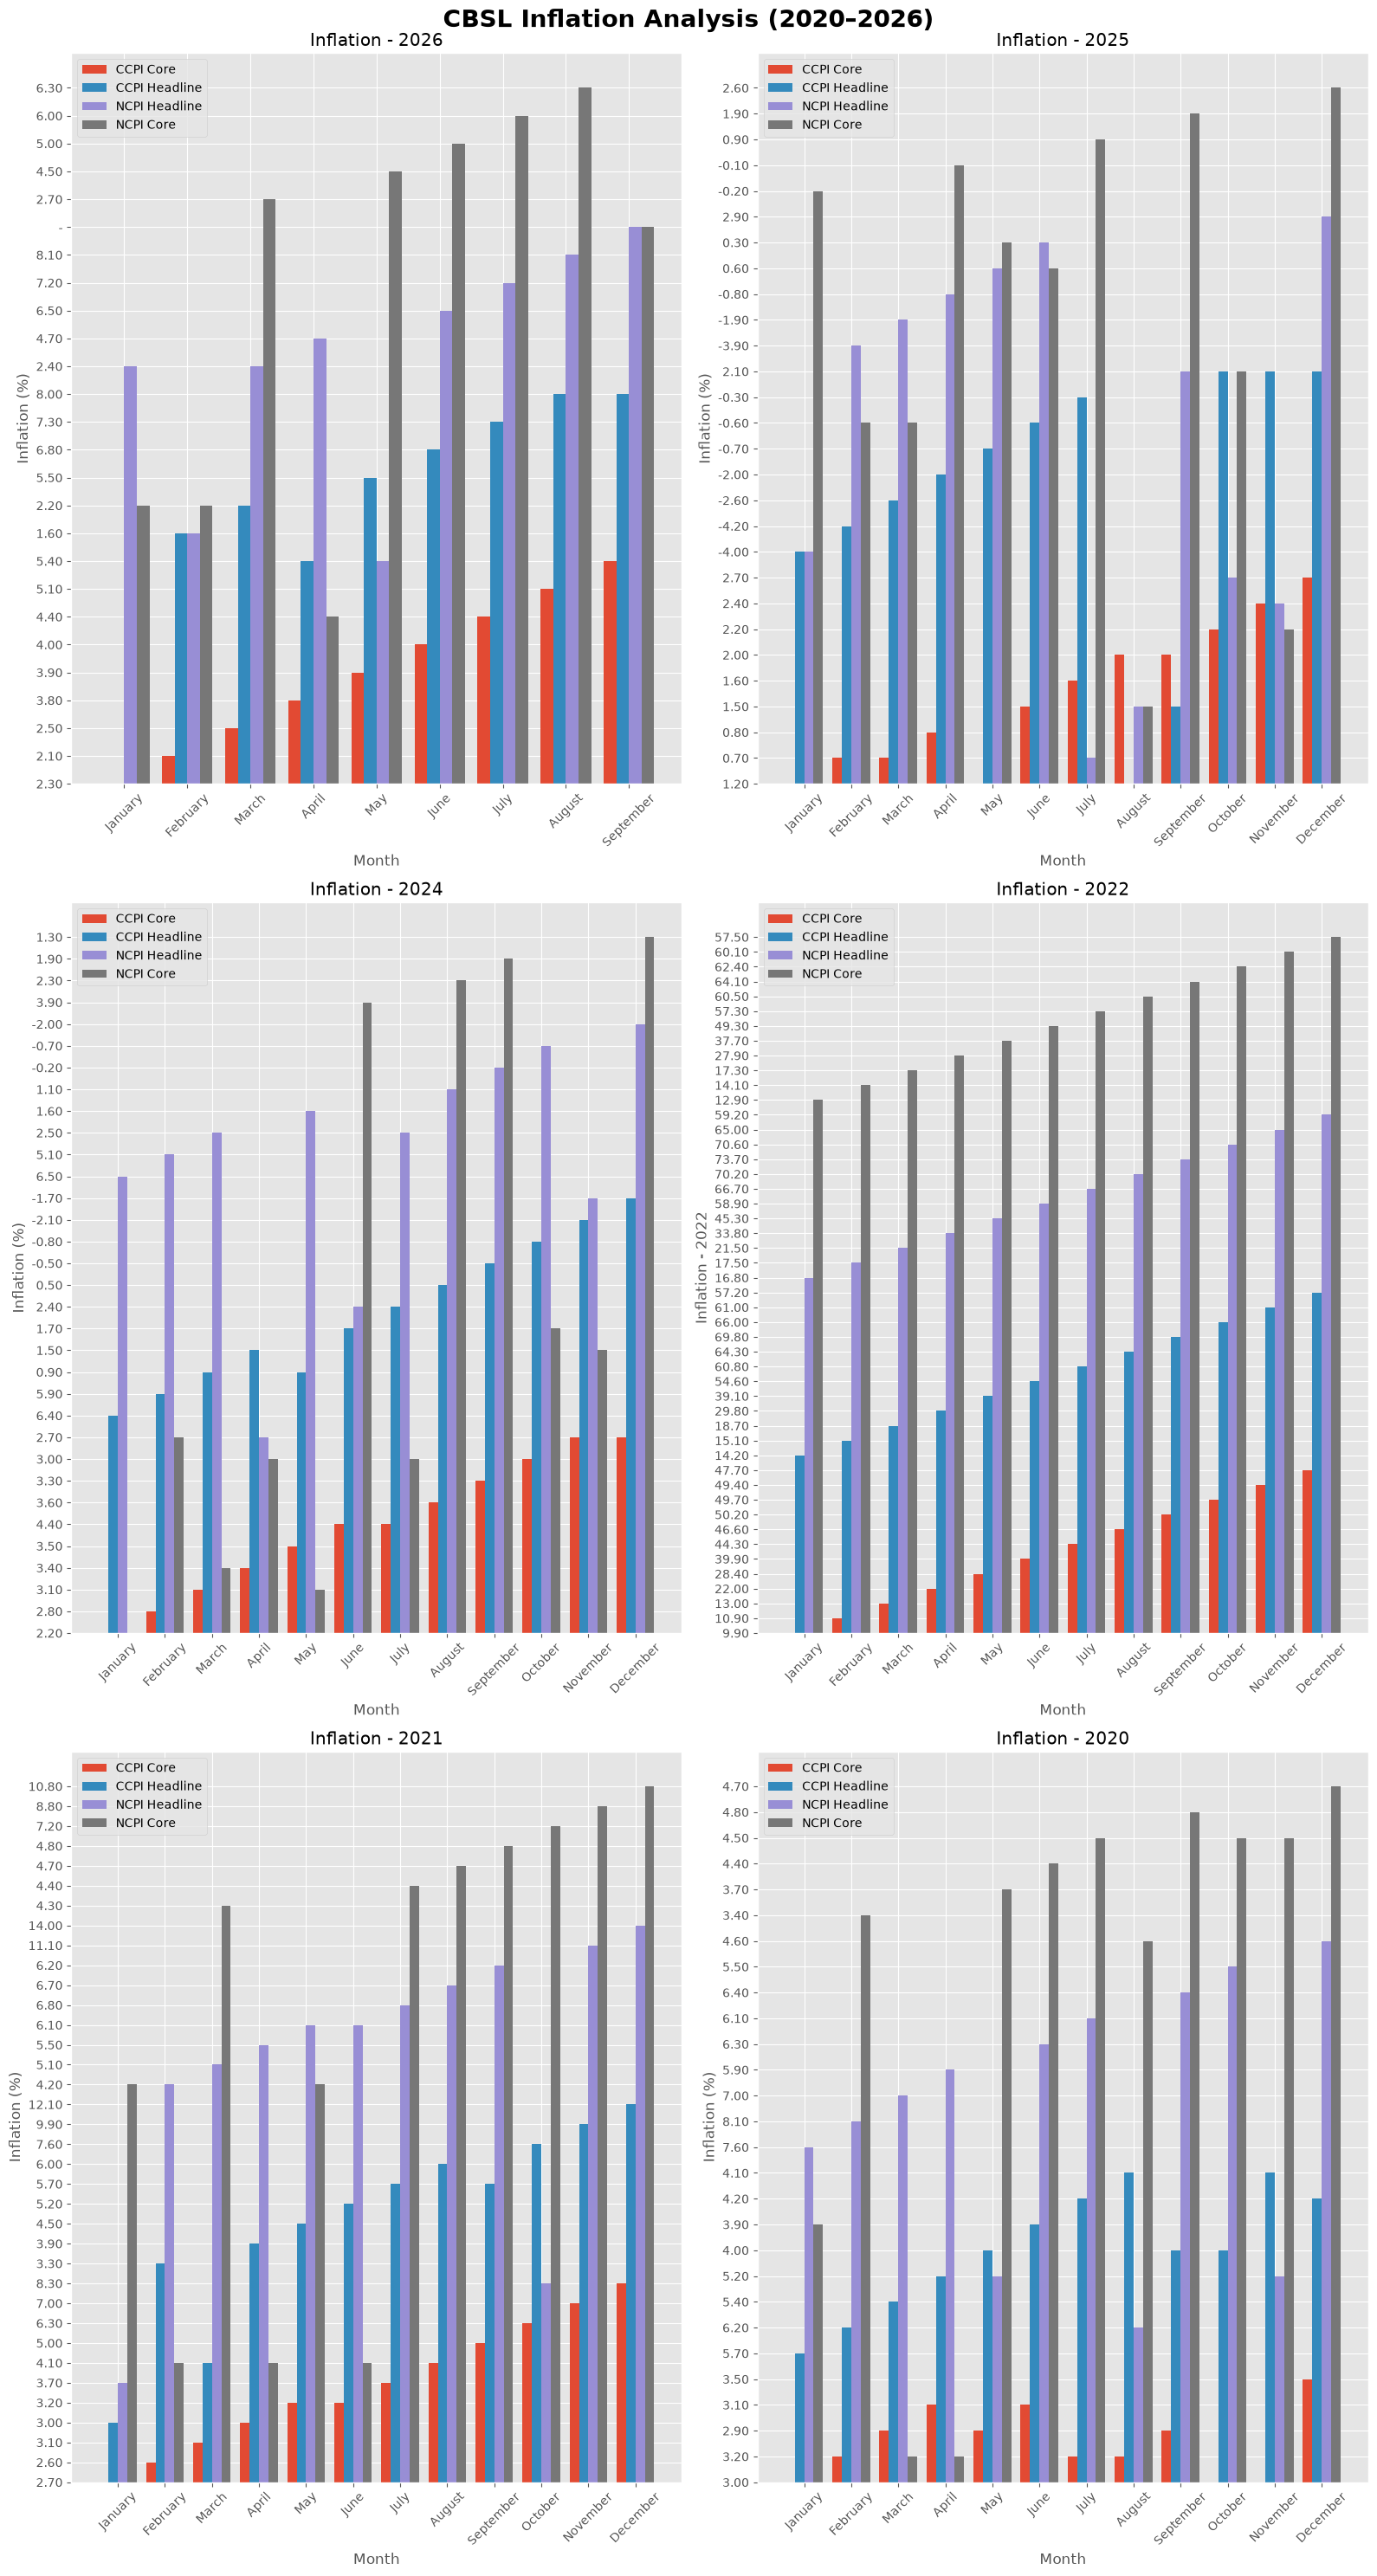

In [141]:
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(nrows=3,ncols=2,figsize=(16, 30))

x = range(len(df_2026))
width = 0.2

# 2026
ax1.bar(
    [i - 1.5*width for i in x],
    df_2026['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax1.bar(
    [i - 0.5*width for i in x],
    df_2026['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax1.bar(
    [i + 0.5*width for i in x],
    df_2026['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax1.bar(
    [i + 1.5*width for i in x],
    df_2026['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax1.set_xticks(x)
ax1.set_xticklabels(df_2026['Date-2026'], rotation=45)
ax1.set(title="Inflation - 2026",
        xlabel="Month",
        ylabel="Inflation (%)")
ax1.legend()

# 2025
x = range(len(df_2025))
width = 0.2

ax2.bar(
    [i - 1.5*width for i in x],
    df_2025['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax2.bar(
    [i - 0.5*width for i in x],
    df_2025['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax2.bar(
    [i + 0.5*width for i in x],
    df_2025['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax2.bar(
    [i + 1.5*width for i in x],
    df_2025['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax2.set_xticks(x)
ax2.set_xticklabels(df_2025['Date-2025'], rotation=45)
ax2.set(title="Inflation - 2025",
        xlabel="Month",
        ylabel="Inflation (%)")
ax2.legend()

#2024
x = range(len(df_2024))
width = 0.2

ax3.bar(
    [i - 1.5*width for i in x],
    df_2024['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax3.bar(
    [i - 0.5*width for i in x],
    df_2024['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax3.bar(
    [i + 0.5*width for i in x],
    df_2024['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax3.bar(
    [i + 1.5*width for i in x],
    df_2024['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax3.set_xticks(x)
ax3.set_xticklabels(df_2024['Date-2024'], rotation=45)
ax3.set(title="Inflation - 2024",
        xlabel="Month",
        ylabel="Inflation (%)")
ax3.legend()

#2022
x = range(len(df_2022))
width = 0.2

ax4.bar(
    [i - 1.5*width for i in x],
    df_2022['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax4.bar(
    [i - 0.5*width for i in x],
    df_2022['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax4.bar(
    [i + 0.5*width for i in x],
    df_2022['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax4.bar(
    [i + 1.5*width for i in x],
    df_2022['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax4.set_xticks(x)
ax4.set_xticklabels(df_2022['Date-2022'], rotation=45)
ax4.set(title="Inflation - 2022",
        xlabel="Month",
        ylabel="Inflation - 2022")
ax4.legend()

#2021
x = range(len(df_2021))
width = 0.2

ax5.bar(
    [i - 1.5*width for i in x],
    df_2021['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax5.bar(
    [i - 0.5*width for i in x],
    df_2021['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax5.bar(
    [i + 0.5*width for i in x],
    df_2021['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax5.bar(
    [i + 1.5*width for i in x],
    df_2021['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax5.set_xticks(x)
ax5.set_xticklabels(df_2021['Date-2021'], rotation=45)
ax5.set(title="Inflation - 2021",
        xlabel="Month",
        ylabel="Inflation (%)")
ax5.legend()

#2020
x = range(len(df_2020))
width = 0.2

ax6.bar(
    [i - 1.5*width for i in x],
    df_2020['CCPI Core Inflation'],
    width=width,
    label='CCPI Core'
)

ax6.bar(
    [i - 0.5*width for i in x],
    df_2020['CCPI Headline Inflation'],
    width=width,
    label='CCPI Headline'
)

ax6.bar(
    [i + 0.5*width for i in x],
    df_2020['NCPI Headline Inflation'],
    width=width,
    label='NCPI Headline'
)

ax6.bar(
    [i + 1.5*width for i in x],
    df_2020['NCPI Core Inflation'],
    width=width,
    label='NCPI Core'
)

ax6.set_xticks(x)
ax6.set_xticklabels(df_2020['Date-2020'], rotation=45)
ax6.set(title="Inflation - 2020",
        xlabel="Month",
        ylabel="Inflation (%)")
ax6.legend()

fig.suptitle(
    "CBSL Inflation Analysis (2020–2026)",
    fontsize=20,
    fontweight='bold',
    y=0.99
)

plt.tight_layout()
plt.show()
fig.savefig(f"{"plots"}/2020-to-2026-all-inflation-analysis.png")


In [142]:
# Rename the first column of each DataFrame to Month
df_2020 = df_2020.rename(columns={df_2020.columns[0]: "Month"})
df_2021 = df_2021.rename(columns={df_2021.columns[0]: "Month"})
df_2022 = df_2022.rename(columns={df_2022.columns[0]: "Month"})
df_2024 = df_2024.rename(columns={df_2024.columns[0]: "Month"})
df_2025 = df_2025.rename(columns={df_2025.columns[0]: "Month"})
df_2026 = df_2026.rename(columns={df_2026.columns[0]: "Month"})

# Add Year
df_2020["Year"] = 2020
df_2021["Year"] = 2021
df_2022["Year"] = 2022
df_2024["Year"] = 2024
df_2025["Year"] = 2025
df_2026["Year"] = 2026

# Combine
df_all = pd.concat([df_2020,df_2021,df_2022,df_2024,df_2025,df_2026], ignore_index=True)
df_all

,Month,CCPI Headline Inflation,CCPI Core Inflation,NCPI Headline Inflation,NCPI Core Inflation,Year
0,January,5.70,3.00,7.60,3.90,2020
1,February,6.20,3.20,8.10,3.40,2020
2,March,5.40,2.90,7.00,3.20,2020
3,April,5.20,3.10,5.90,3.20,2020
4,May,4.00,2.90,5.20,3.70,2020
...,...,...,...,...,...,...
64,May,5.50,3.90,5.40,4.50,2026
65,June,6.80,4.00,6.50,5.00,2026
66,July,7.30,4.40,7.20,6.00,2026
67,August,8.00,5.10,8.10,6.30,2026


In [143]:
# Check current data types
print(df_all.dtypes,"\n")

# Change data types
df_all["Month"] = df_all["Month"].astype(str)
df_all["Year"] = pd.to_numeric(df_all["Year"], errors="coerce").astype("Int64")

df_all["CCPI Headline Inflation"] = pd.to_numeric(df_all["CCPI Headline Inflation"], errors="coerce")

df_all["CCPI Core Inflation"] = pd.to_numeric(df_all["CCPI Core Inflation"], errors="coerce")

df_all["NCPI Headline Inflation"] = pd.to_numeric(df_all["NCPI Headline Inflation"], errors="coerce")

df_all["NCPI Core Inflation"] = pd.to_numeric(df_all["NCPI Core Inflation"], errors="coerce")

# Check after conversion
print(df_all.dtypes)

Month                        str
CCPI Headline Inflation      str
CCPI Core Inflation          str
NCPI Headline Inflation      str
NCPI Core Inflation          str
Year                       int64
dtype: object 

Month                          str
CCPI Headline Inflation    float64
CCPI Core Inflation        float64
NCPI Headline Inflation    float64
NCPI Core Inflation        float64
Year                         Int64
dtype: object


In [144]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

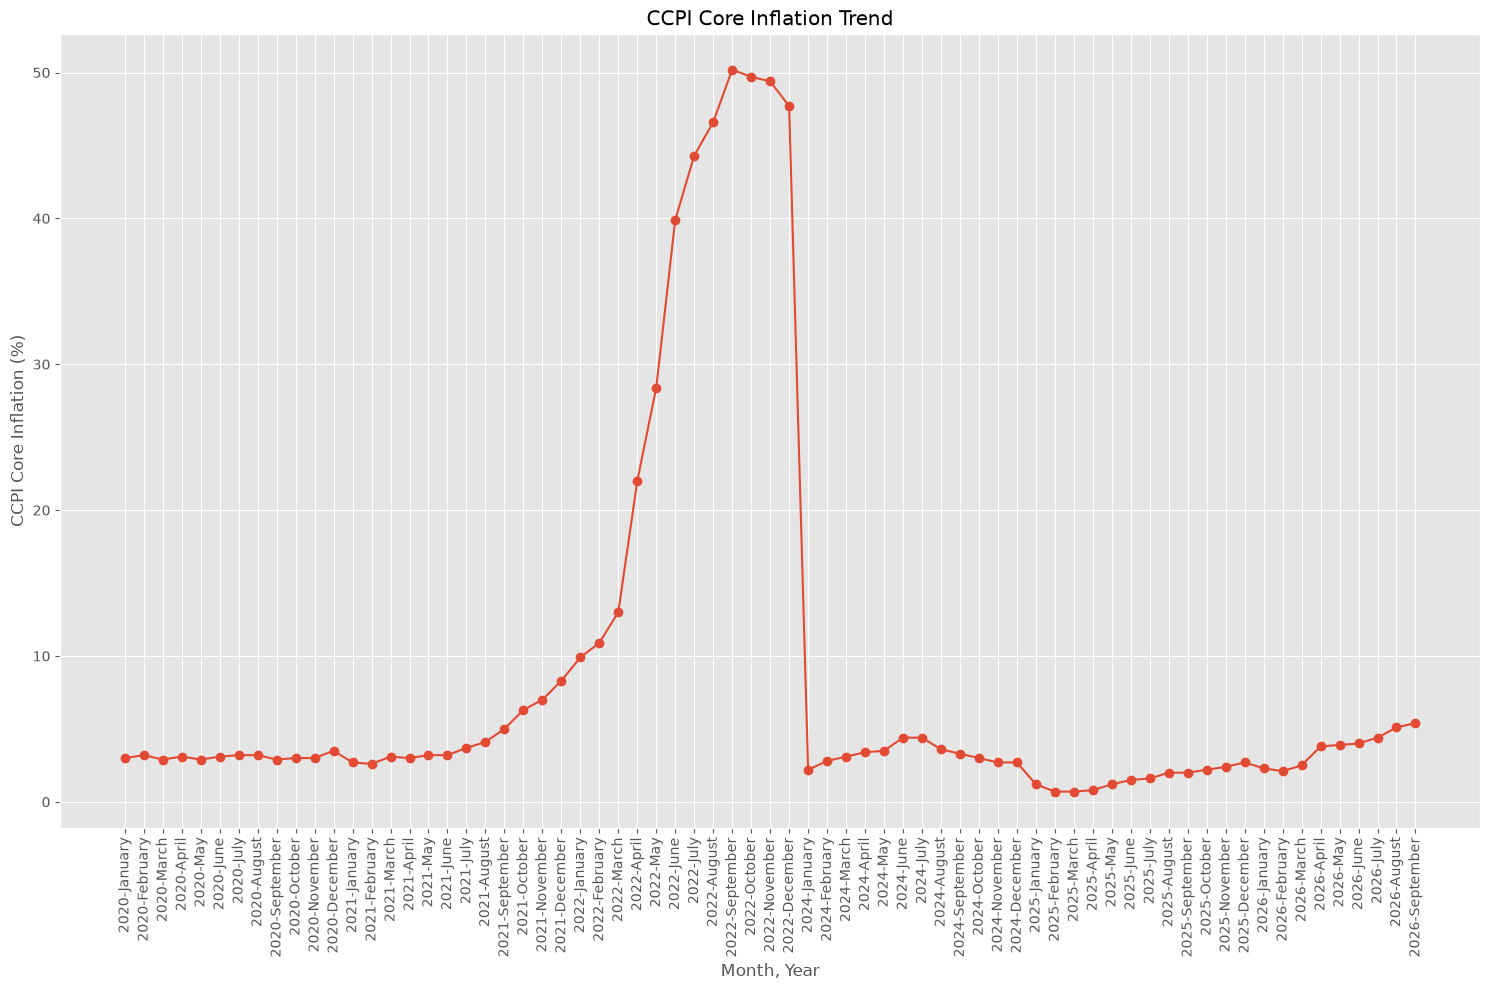

<Figure size 640x480 with 0 Axes>

In [145]:
df_all['Year-Month'] = df_all['Year'].astype(str) + "-" + df_all['Month']
df_all

# CCPI Core Inflation
plt.style.use("ggplot")
plt.figure(figsize=(15, 10))
plt.plot(df_all["Year-Month"],df_all["CCPI Core Inflation"],marker="o")
plt.xlabel("Month, Year")
plt.ylabel("CCPI Core Inflation (%)")
plt.title("CCPI Core Inflation Trend") 
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(f"{"plots"}/CCPI-Core-Inflation-Trend.png")

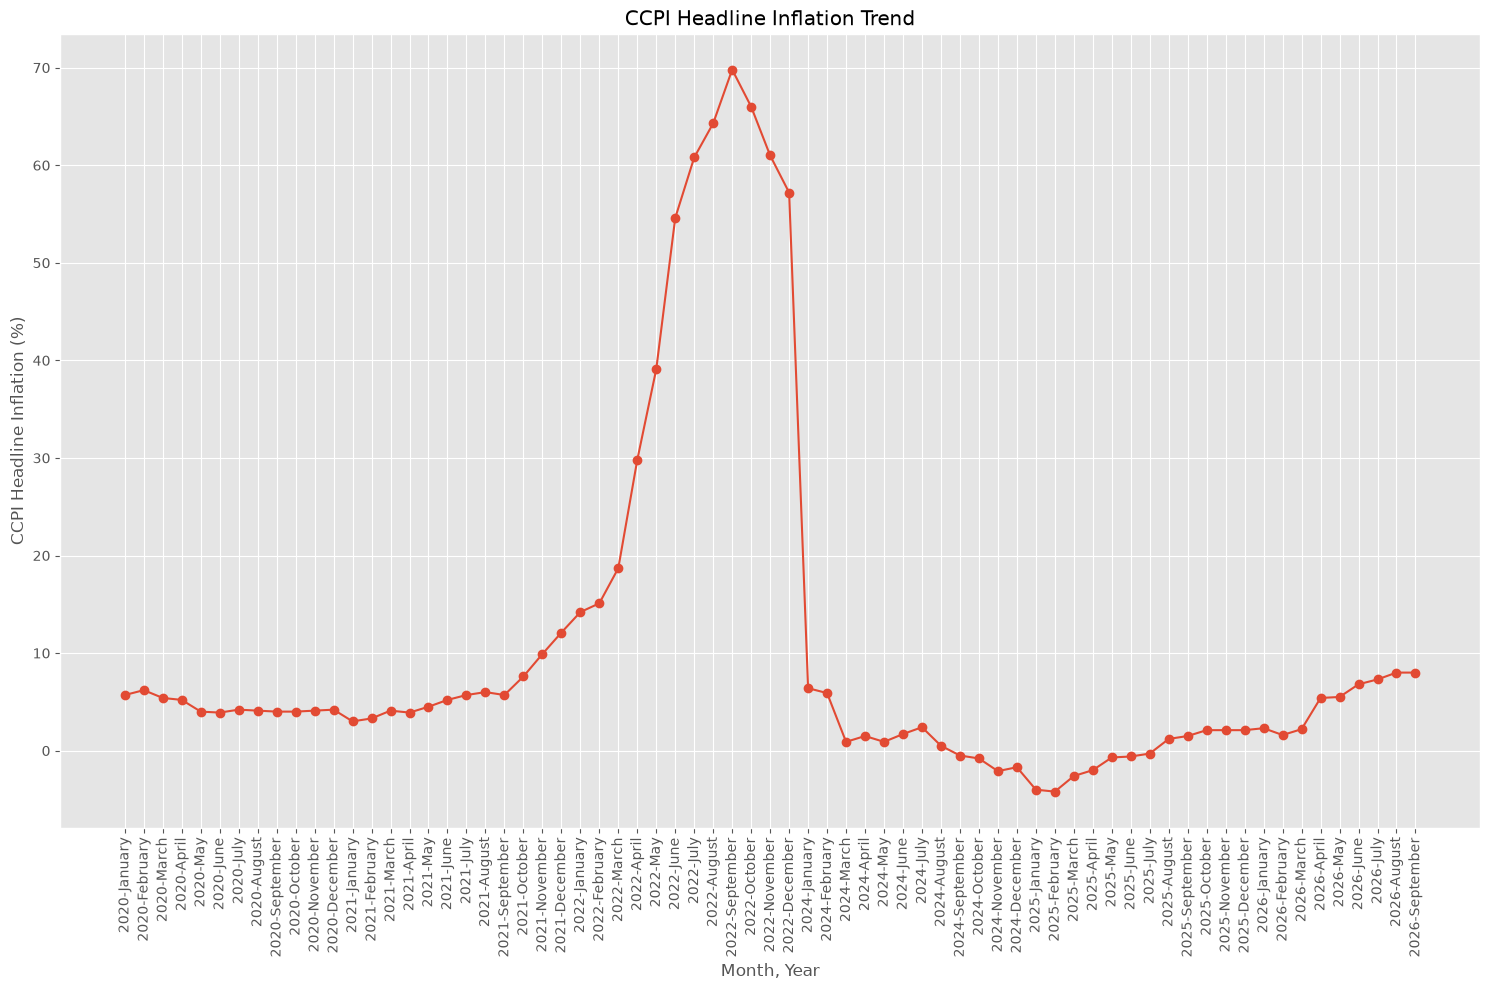

<Figure size 640x480 with 0 Axes>

In [ ]:
# CCPI Headline Inflation
plt.figure(figsize=(15, 10))
plt.plot(df_all["Year-Month"],df_all["CCPI Headline Inflation"],marker="o")
plt.xlabel("Month, Year")
plt.ylabel("CCPI Headline Inflation (%)")
plt.title("CCPI Headline Inflation Trend") 
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(f"{"plots"}/CCPI-Headline-Inflation-Trend.png")

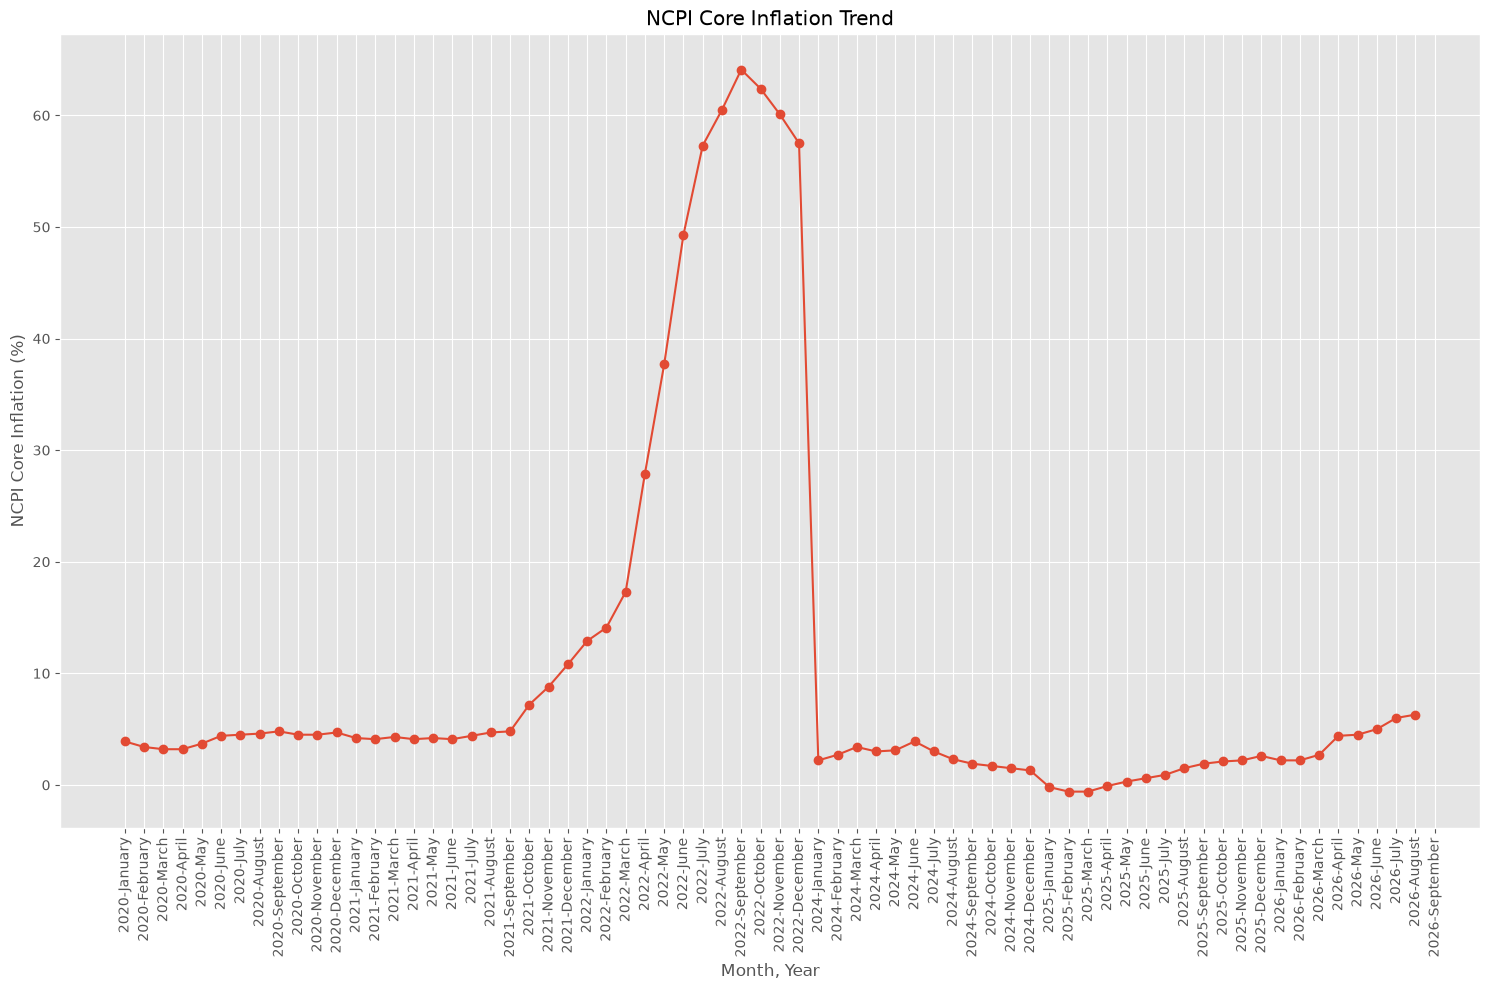

<Figure size 640x480 with 0 Axes>

In [147]:
# NCPI Core Inflation

plt.figure(figsize=(15, 10))
plt.plot(df_all["Year-Month"],df_all["NCPI Core Inflation"],marker="o")
plt.xlabel("Month, Year")
plt.ylabel("NCPI Core Inflation (%)")
plt.title("NCPI Core Inflation Trend") 
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(f"{"plots"}/NCPI-Core-Inflation-Trend.png")

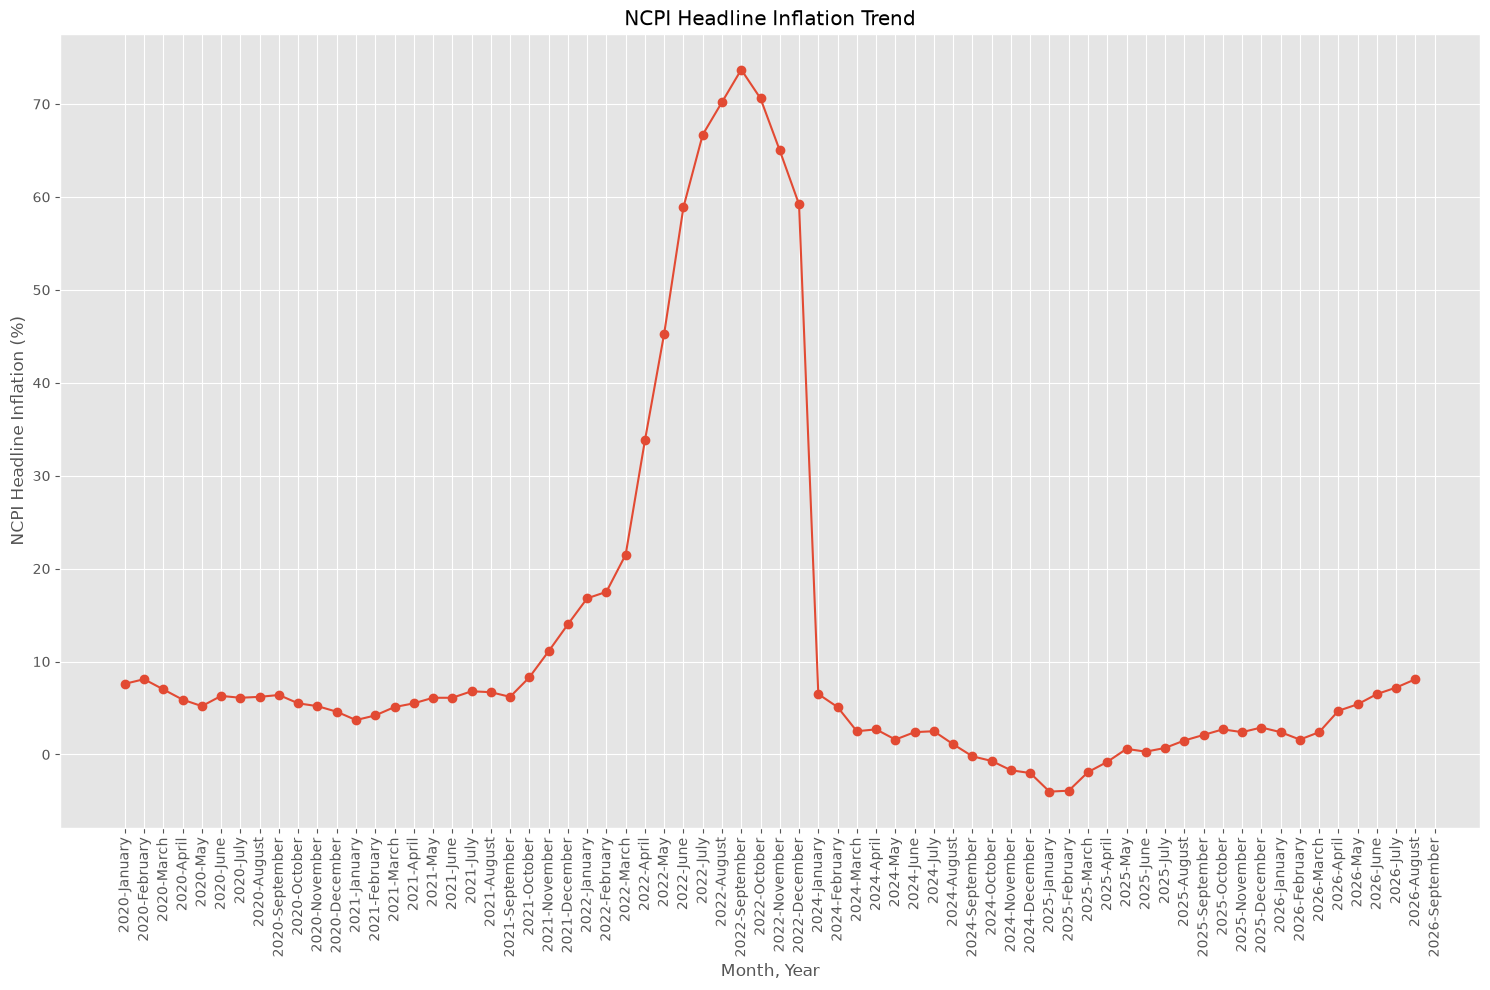

<Figure size 640x480 with 0 Axes>

In [148]:
# NCPI Headline Inflation

plt.figure(figsize=(15, 10))
plt.plot(df_all["Year-Month"],df_all["NCPI Headline Inflation"],marker="o")
plt.xlabel("Month, Year")
plt.ylabel("NCPI Headline Inflation (%)")
plt.title("NCPI Headline Inflation Trend") 
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(f"{"plots"}/NCPI-Headline-Inflation-Trend.png")

In [149]:
df_all.to_csv("all-inflation.csv",index=False)

# Monetary Policy

In [150]:
# Original one
monetary_links = relevant_links[relevant_links["category"] == "Monetary Policy"].copy()

display(monetary_links.head(20))

,link_type,link_text,url,source_page,category
21,a,MONETARY POLICY,https://www.cbsl.gov.lk/en/monetary-policy-2026,https://www.cbsl.gov.lk/,Monetary Policy
87,a,Monetary Sector,https://www.cbsl.gov.lk/en/statistics/statistical-tables/monetary-sector,https://www.cbsl.gov.lk/,Monetary Policy
109,a,Monetary Policy Review,https://www.cbsl.gov.lk/en/press/press-releases/monetary-policy-review,https://www.cbsl.gov.lk/,Monetary Policy
122,a,Monetary Policy Report,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports,https://www.cbsl.gov.lk/,Monetary Policy
200,a,Privacy,https://www.cbsl.gov.lk/en/privacy-policy-statement,https://www.cbsl.gov.lk/,Monetary Policy
222,a,"Monetary Law Act, No. 58 of 1949 (Incorporating Amendments up to 30th June, 2014)",https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/laws/acts/en/monetary_law_act.pdf,https://www.cbsl.gov.lk/en/laws/acts/legislative-enactments,Monetary Policy
252,a,Skip to main content,https://www.cbsl.gov.lk/en/monetary-policy-2026#main-content,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
255,a,ABOUT,https://www.cbsl.gov.lk/en/monetary-policy-2026#,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
256,a,NaN,https://www.cbsl.gov.lk/en/rates-and-indicators/policy-rates,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
258,a,NaN,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/about/monetary_policy_framework_agreement_2308_28_e.pdf,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy


In [151]:
policy_pdf_links = monetary_links[
    monetary_links["url"].str.contains(
        r"\.pdf($|\?)",
        case=False,
        na=False,
        regex=True
    )
].copy()

display(policy_pdf_links)
print("Number of PDF links found:",len(policy_pdf_links))

C:\Users\pc\AppData\Local\Temp\ipykernel_11324\622139571.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  monetary_links["url"].str.contains(


,link_type,link_text,url,source_page,category
222,a,"Monetary Law Act, No. 58 of 1949 (Incorporating Amendments up to 30th June, 2014)",https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/laws/acts/en/monetary_law_act.pdf,https://www.cbsl.gov.lk/en/laws/acts/legislative-enactments,Monetary Policy
258,a,NaN,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/about/monetary_policy_framework_agreement_2308_28_e.pdf,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
268,a,Press Release,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/press/pr/press_20250924_Monetary_Policy_Review_No_5_2025_e_Dx7f6.pdf,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
269,a,Presentation,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/monetary_policy/mpr_no_5_press_presentation_e.pdf,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
272,a,Press Release,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/press/pr/press_20251126_Monetary_Policy_Review_No_6_2025_e_Ey8g7.pdf,https://www.cbsl.gov.lk/en/monetary-policy-2026,Monetary Policy
...,...,...,...,...,...
728,a,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary_policy_report_2024_february_e.pdf,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2024-february,Monetary Policy
733,a,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary_policy_report_2025_february_e.pdf,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2025-february,Monetary Policy
738,a,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary_policy_report_2025_august_e.pdf,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2025-august,Monetary Policy
743,a,Full Text,https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary-policy-report-2026-august.pdf,https://www.cbsl.gov.lk/en/publications/economic-and-financial-reports/monetary-policy-reports/monetary-policy-report-2026-august,Monetary Policy


Number of PDF links found: 134


In [152]:
policy_pdf_links.to_csv("CBSL_Monetary_Policy_PDF_Links.csv",index=False)

In [153]:
if len(policy_pdf_links) > 0:
    print(f"{len(policy_pdf_links)} PDF URL:")
    print(policy_pdf_links.iloc[132]["url"])

else:
    print("No PDF links found.")

134 PDF URL:
https://www.cbsl.gov.lk/sites/default/files/cbslweb_documents/publications/monetary-policy-report-2026-august.pdf


In [154]:
pdf_url = policy_pdf_links.iloc[132]["url"]
pdf_response = requests.get(
    pdf_url,
    headers=HEADERS,
    timeout=60
)

pdf_response.raise_for_status()
print("PDF Status:",pdf_response.status_code)
with open("CBSL_Monetary_Policy.pdf","wb") as file:
    file.write(pdf_response.content)

PDF Status: 200


In [155]:
print("Downloaded bytes:",len(pdf_response.content))

Downloaded bytes: 1458962


In [156]:
reader = PdfReader("CBSL_Monetary_Policy.pdf")

In [157]:
print("Number of pages:",len(reader.pages))

Number of pages: 51


In [158]:
pdf_text = ""

for page_number, page in enumerate(reader.pages,start=1):
    page_text = (page.extract_text() or "")
    pdf_text += (f"\n--- PAGE {page_number} ---\n" + page_text)


In [159]:
print(pdf_text[:5000])


--- PAGE 1 ---
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
  

--- PAGE 2 ---
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
The Monetary Policy Report is a biannual publication. The content of the current Report is based 
on the data available as of the July 2026 monetary policy round of the Central Bank, which 
concluded with the monetary policy announcement on 22 July 2026. 
 
© Central Bank of Sri Lanka 
ISBN 978-624-6764-38-8 
13 August 2026 
 
--- PAGE 3 ---
TABLE OF CONTENTS  
MONETARY POLICY FRAMEWORK OF THE CENTRAL BANK OF SRI LANKA ............. 4 
EXECUTIVE SUMMARY ......................................................................................... 6 
1. MONETARY POLICY SUMMARY ........................................................................ 8 
2. INFLATION AND ECONOMIC OUTLOOK .......................................................... 10 
2.1. Baseline Forecast .................................................................................. 10 
Prospects for Inflatio

In [70]:
print("Characters extracted:",len(pdf_text.strip()))

Characters extracted: 98415


In [160]:
!tesseract --list-langs

List of available languages in "F:\My PC\Applied Data Analysis\Second year\DA 2009\day 8 (23.08.2026)/tessdata/" (2):
eng
osd


In [161]:
for page_number, page in enumerate(reader.pages,start=1):
    try:
        images = list(page.images)
        print("Page",page_number,"- Images found:",len(images))

    except Exception as e:
        print("Page",page_number,"- Could not inspect images:",e)

Page 1 - Images found: 1
Page 2 - Images found: 0
Page 3 - Images found: 0
Page 4 - Images found: 0
Page 5 - Images found: 1
Page 6 - Images found: 0
Page 7 - Images found: 0
Page 8 - Images found: 0
Page 9 - Images found: 8
Page 10 - Images found: 0
Page 11 - Images found: 5
Page 12 - Images found: 4
Page 13 - Images found: 0
Page 14 - Images found: 0
Page 15 - Images found: 0
Page 16 - Images found: 4
Page 17 - Images found: 0
Page 18 - Images found: 2
Page 19 - Images found: 0
Page 20 - Images found: 0
Page 21 - Images found: 0
Page 22 - Images found: 5
Page 23 - Images found: 0
Page 24 - Images found: 3
Page 25 - Images found: 1
Page 26 - Images found: 0
Page 27 - Images found: 0
Page 28 - Images found: 0
Page 29 - Images found: 0
Page 30 - Images found: 0
Page 31 - Images found: 0
Page 32 - Images found: 0
Page 33 - Images found: 0
Page 34 - Images found: 0
Page 35 - Images found: 0
Page 36 - Images found: 1
Page 37 - Images found: 0
Page 38 - Images found: 0
Page 39 - Images foun

In [162]:
os.makedirs("extracted_pdf_images",exist_ok=True)

In [163]:
image_records = []

for page_number, page in enumerate(reader.pages,start=1):

    try:
        images = list(page.images)

        for image_number, image_file in enumerate(images,start=1):
            filename = f"extracted_pdf_images/page_{page_number}_image_{image_number}.png"

            # image_file.image is a PIL Image
            pil_image = image_file.image

            pil_image.save(filename)

            image_records.append({
                "page":page_number,
                "image":image_number,
                "filename":filename
            })

            print("Saved:",filename)

    except Exception as e:
        print("Error on page",page_number,":",e)

Saved: extracted_pdf_images/page_1_image_1.png
Saved: extracted_pdf_images/page_5_image_1.png
Saved: extracted_pdf_images/page_9_image_1.png
Saved: extracted_pdf_images/page_9_image_2.png
Saved: extracted_pdf_images/page_9_image_3.png
Saved: extracted_pdf_images/page_9_image_4.png
Saved: extracted_pdf_images/page_9_image_5.png
Saved: extracted_pdf_images/page_9_image_6.png
Saved: extracted_pdf_images/page_9_image_7.png
Saved: extracted_pdf_images/page_9_image_8.png
Saved: extracted_pdf_images/page_11_image_1.png
Saved: extracted_pdf_images/page_11_image_2.png
Saved: extracted_pdf_images/page_11_image_3.png
Saved: extracted_pdf_images/page_11_image_4.png
Saved: extracted_pdf_images/page_11_image_5.png
Saved: extracted_pdf_images/page_12_image_1.png
Saved: extracted_pdf_images/page_12_image_2.png
Saved: extracted_pdf_images/page_12_image_3.png
Saved: extracted_pdf_images/page_12_image_4.png
Saved: extracted_pdf_images/page_16_image_1.png
Saved: extracted_pdf_images/page_16_image_2.png
Sa

In [164]:
print("Total images extracted:",len(image_records))

Total images extracted: 36


In [165]:
image_ocr_results = []

for record in image_records:
    
    filename = record["filename"]
    image = Image.open(filename)
    text = pytesseract.image_to_string(image,lang="eng+sin")

    image_ocr_results.append({
        "page":record["page"],
        "image":record["image"],
        "filename":filename,
        "ocr_text":text
    })

    print("\n----------------------")
    print("Page:",record["page"])

    print("Image:",record["image"])

    print("OCR Text:")

    print(text[:2000])


----------------------
Page: 1
Image: 1
OCR Text:
MONETARY

POLICY REPORT |
AUGUST 2026

G E0%) OH Qz02zyV®O
Qovtions wHswi ound
CENTRAL BANK OF SRI LANKA



----------------------
Page: 5
Image: 1
OCR Text:
Market Operations

‘Committee
Staff-Level MPC Meeti Release of (moc)
Meetings Tier 1 Tier 2 Monetary Policy Myoung
(Technical (Technical , wa decisions
Level Open Level Closed Chair - Governor Decision
Session) Session) Presentation on:
ess * + Medium-term projections,
Issue-based — Medium-term * Risks to outlook Published
technical _ projections + Scenario analyses biannually
presentation and risks to Macroeconomic Assessment
with risks outlook On or before 15 February
MPB considers MPC and 15 August, following
\ recommendations and the release of January and
decides on the monetary July monetary policy
First Staff Ww policy stance decisions, respectively
Level Second | 7X
Meeting staff Level Chair - Governor WwW
‘ Presentation on: Monetary policy
Macroeconomic — Meeting + Medium

In [77]:
image_ocr_df = pd.DataFrame(image_ocr_results)

In [166]:
display(image_ocr_df[["page","image","ocr_text"]])

,page,image,ocr_text
0,1,1,MONETARY\n\nPOLICY REPORT |\nAUGUST 2026\n\nG E0%) OH Qz02zyV®O\nQovtions wHswi ound\nCENTRAL BANK OF SRI LANKA\n\n
1,5,1,"Market Operations\n\n‘Committee\nStaff-Level MPC Meeti Release of (moc)\nMeetings Tier 1 Tier 2 Monetary Policy Myoung\n(Technical (Technical , wa decisions\nLevel Open Level Closed Chair - Governor Decision\nSession) Session) Presentation on:\ness * + Medium-term projections,\nIssue-based — Medium-term * Risks to outlook Published\ntechnical _ projections + Scenario analyses biannually\npresentation and risks to Macroeconomic Assessment\nwith risks outlook On or before 15 February\nMPB considers MPC and 15 August, following\n\ recommendations and the release of January and\ndecides on the monetary July monetary policy\nFirst Staff Ww policy stance decisions, respectively\nLevel Second | 7X\nMeeting staff Level Chair - Governor WwW\n‘ Presentation on: Monetary policy\nMacroeconomic — Meeting + Medium-term projections, i\nreview by "" pr o C review press\ninnit * Ri te itl\nmacroeconomic c lyst following day of\nprojections Macroeconomic Assessment MPB meeting\nand risks to Pre-MPC MPC makes Policy\noutlook . Monetary\nMeeting Monetary Policy Stance SJ} poticy press\n\nChair - Governor\nObservers - MPB members\n\n] conference\n\nec Monetary\n\nPolicy Report\n\nMPB\nMeeting\n"
2,9,1,
3,9,2,
4,9,3,
5,9,4,
6,9,5,
7,9,6,
8,9,7,
9,9,8,


# Thank You 😊😊